In [ ]:
# Create time-based features

# why cyclical encoding?

# Think about hours on a clock. Hour 23 and hour 0 are only one hour apart, but a machine learning model might treat them as very different numbers.
# Sine and cosine help represent their circular relationship.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/iex_dam_2025_clean.csv",
    parse_dates=["timestamp"]
)

df = df.sort_values("timestamp").reset_index(drop=True)

# Identify the 15-minute slot (0 to 95)
df["time_slot"] = df["hour"] * 4 + df["minute"] // 15

# Cyclical encoding of time of day
df["time_sin"] = np.sin(2 * np.pi * df["time_slot"] / 96)
df["time_cos"] = np.cos(2 * np.pi * df["time_slot"] / 96)

# Cyclical encoding of day of week
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

# Cyclical encoding of month
df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

print(df[[
    "timestamp", "hour", "day_of_week",
    "time_slot", "time_sin", "time_cos",
    "dow_sin", "dow_cos"
]].head())

            timestamp  hour  day_of_week  time_slot  time_sin  time_cos  \
0 2025-01-01 00:00:00     0            2          0  0.000000  1.000000   
1 2025-01-01 00:15:00     0            2          1  0.065403  0.997859   
2 2025-01-01 00:30:00     0            2          2  0.130526  0.991445   
3 2025-01-01 00:45:00     0            2          3  0.195090  0.980785   
4 2025-01-01 01:00:00     1            2          4  0.258819  0.965926   

    dow_sin   dow_cos  
0  0.974928 -0.222521  
1  0.974928 -0.222521  
2  0.974928 -0.222521  
3  0.974928 -0.222521  
4  0.974928 -0.222521  


In [ ]:
# Create lag features
# This is one of the most important steps for electricity price forecasting.

# We'll use:
# - lag_1_day: Price at the same 15-minute interval yesterday.
# - lag_7_days: Price at the same 15-minute interval last week.

In [2]:
# 96 intervals per day (24 hours × 4)
INTERVALS_PER_DAY = 96

# Previous day, same 15-minute interval
df["lag_1_day"] = df["price_inr_mwh"].shift(96)

# Previous week, same 15-minute interval
df["lag_7_days"] = df["price_inr_mwh"].shift(672)

print(df[[
    "timestamp",
    "price_inr_mwh",
    "lag_1_day",
    "lag_7_days"
]].head(700))

              timestamp  price_inr_mwh  lag_1_day  lag_7_days
0   2025-01-01 00:00:00        2330.10        NaN         NaN
1   2025-01-01 00:15:00        2300.07        NaN         NaN
2   2025-01-01 00:30:00        2300.13        NaN         NaN
3   2025-01-01 00:45:00        2265.65        NaN         NaN
4   2025-01-01 01:00:00        2191.43        NaN         NaN
..                  ...            ...        ...         ...
695 2025-01-08 05:45:00        3170.03    3110.39     2699.60
696 2025-01-08 06:00:00        3573.53    3570.69     2927.99
697 2025-01-08 06:15:00        3871.73    3841.60     3185.60
698 2025-01-08 06:30:00        4328.49    4200.18     3241.21
699 2025-01-08 06:45:00        5200.19    4459.18     3241.30

[700 rows x 4 columns]


In [ ]:
# Create rolling statistical features
# Rolling features help the model understand recent price behaviour.

In [3]:
# Use historical data ending no later than the previous day
historical_prices = df["price_inr_mwh"].shift(96)

# Average price over the previous 7 days
df["rolling_7d_mean"] = (
    historical_prices
    .rolling(window=7 * 96, min_periods=7 * 96)
    .mean()
)

# Price volatility over the previous 7 days
df["rolling_7d_std"] = (
    historical_prices
    .rolling(window=7 * 96, min_periods=7 * 96)
    .std()
)

print(df[[
    "timestamp",
    "price_inr_mwh",
    "rolling_7d_mean",
    "rolling_7d_std"
]].tail())

                timestamp  price_inr_mwh  rolling_7d_mean  rolling_7d_std
35035 2025-12-31 22:45:00        3626.43      4179.356295     2309.355403
35036 2025-12-31 23:00:00        3200.18      4179.282336     2309.394070
35037 2025-12-31 23:15:00        3107.80      4179.171503     2309.454256
35038 2025-12-31 23:30:00        3100.06      4179.219063     2309.427326
35039 2025-12-31 23:45:00        2964.01      4179.219152     2309.427272


In [ ]:
# Prepare the modelling dataset
# We'll retain only features that are appropriate for our day-ahead forecasting setup.

In [4]:
feature_columns = [
    # Calendar features
    "time_slot",
    "is_weekend",
    "time_sin",
    "time_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",

    # Historical price features
    "lag_1_day",
    "lag_7_days",

    # Rolling features
    "rolling_7d_mean",
    "rolling_7d_std"
]

target_column = "price_inr_mwh"

model_df = df[
    ["timestamp"] + feature_columns + [target_column]
].copy()

# Remove rows without sufficient historical data
model_df = model_df.dropna().reset_index(drop=True)

print("Original dataset:", df.shape)
print("Modelling dataset:", model_df.shape)

print("\nFeatures:")
print(feature_columns)

display(model_df.head())

Original dataset: (35040, 26)
Modelling dataset: (34273, 14)

Features:
['time_slot', 'is_weekend', 'time_sin', 'time_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'lag_1_day', 'lag_7_days', 'rolling_7d_mean', 'rolling_7d_std']


,timestamp,time_slot,is_weekend,time_sin,time_cos,dow_sin,dow_cos,month_sin,month_cos,lag_1_day,lag_7_days,rolling_7d_mean,rolling_7d_std,price_inr_mwh
0,2025-01-08 23:45:00,95,0,-0.065403,0.997859,0.974928,-0.222521,0.0,1.0,2699.35,2510.32,4118.202619,2365.412385,2769.07
1,2025-01-09 00:00:00,0,0,0.000000,1.000000,0.433884,-0.900969,0.0,1.0,2522.96,2232.08,4118.489613,2365.206803,2927.30
2,2025-01-09 00:15:00,1,0,0.065403,0.997859,0.433884,-0.900969,0.0,1.0,2449.97,2178.43,4118.712679,2365.042113,2898.16
3,2025-01-09 00:30:00,2,0,0.130526,0.991445,0.433884,-0.900969,0.0,1.0,2449.04,2161.35,4118.934271,2364.878437,2820.44
4,2025-01-09 00:45:00,3,0,0.195090,0.980785,0.433884,-0.900969,0.0,1.0,2330.11,2143.72,4119.030193,2364.804460,2800.89


In [5]:
from pathlib import Path

output_path = Path("../data/processed/iex_dam_2025_features.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

model_df.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: ../data/processed/iex_dam_2025_features.csv


In [ ]:
# Chronological train-validation-test split

# We'll use:
# Dataset	    Period	        Purpose
# Training	    Jan–Sep 2025	Train the model
# Validation	Oct–Nov 2025	Compare and tune models
# Testing	    Dec 2025	    Final evaluation

In [7]:
# Extract delivery date
model_df["delivery_date"] = model_df["timestamp"].dt.date

# Chronological split
train_df = model_df[
    model_df["timestamp"] < "2025-10-01"
]

val_df = model_df[
    (model_df["timestamp"] >= "2025-10-01") &
    (model_df["timestamp"] < "2025-12-01")
]

test_df = model_df[
    model_df["timestamp"] >= "2025-12-01"
]

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

Training records: 25441
Validation records: 5856
Testing records: 2976


In [ ]:
# Build a simple baseline model

# Our first baseline will be:
# Tomorrow's price = Yesterday's price at the same 15-minute interval.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_model(actual, predicted, name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print(f"\n{name}")
    print(f"MAE:  ₹{mae:.2f}/MWh")
    print(f"RMSE: ₹{rmse:.2f}/MWh")

    return {"Model": name, "MAE": mae, "RMSE": rmse}


# Previous-day baseline
baseline_predictions = test_df["lag_1_day"]

baseline_results = evaluate_model(
    test_df["price_inr_mwh"],
    baseline_predictions,
    "Previous Day Baseline"
)


Previous Day Baseline
MAE:  ₹532.58/MWh
RMSE: ₹1180.17/MWh


In [10]:
weekly_results = evaluate_model(
    test_df["price_inr_mwh"],
    test_df["lag_7_days"],
    "Previous Week Baseline"
)


Previous Week Baseline
MAE:  ₹559.54/MWh
RMSE: ₹1054.96/MWh


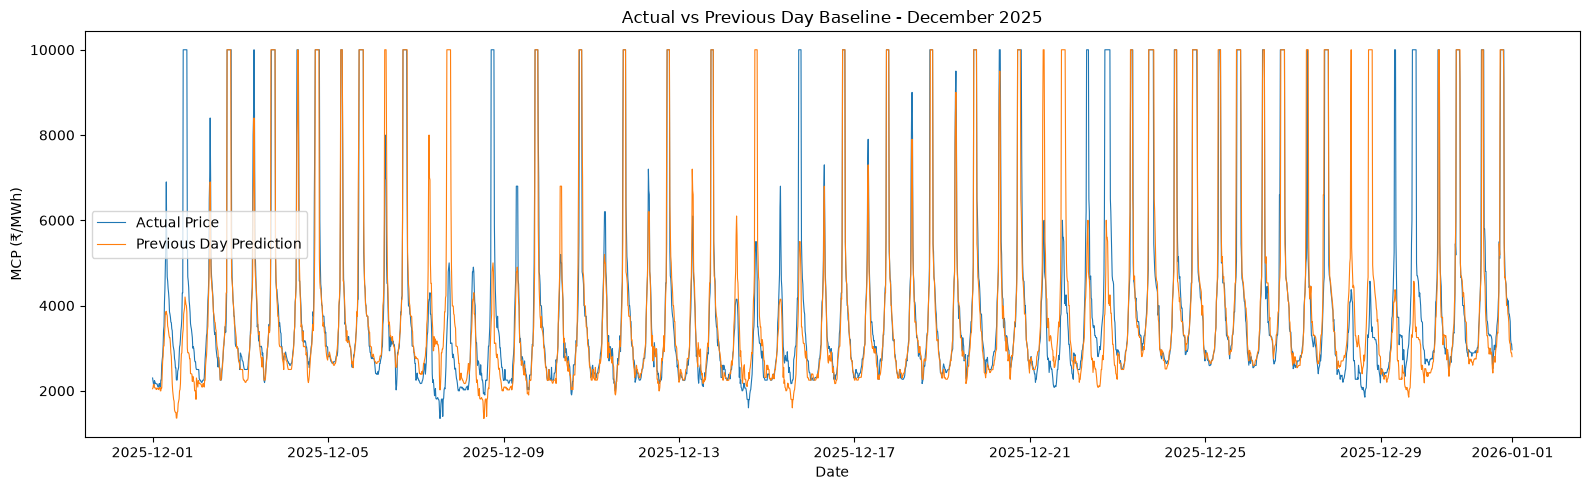

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))

plt.plot(
    test_df["timestamp"],
    test_df["price_inr_mwh"],
    label="Actual Price",
    linewidth=0.8
)

plt.plot(
    test_df["timestamp"],
    test_df["lag_1_day"],
    label="Previous Day Prediction",
    linewidth=0.8
)

plt.title("Actual vs Previous Day Baseline - December 2025")
plt.xlabel("Date")
plt.ylabel("MCP (₹/MWh)")
plt.legend()
plt.tight_layout()
plt.show()